# Fragment Processing

## Setup

Download the PBMC 5k ATAC-seq dataset from 10x Genomics if you haven't already:

In [1]:
%%bash
[ -f data/pbmc_fragments.tsv.gz ] || wget -O data/pbmc_fragments.tsv.gz https://cf.10xgenomics.com/samples/cell-atac/2.0.0/atac_pbmc_5k_nextgem/atac_pbmc_5k_nextgem_fragments.tsv.gz
[ -f data/gencode.v44.primary_assembly.annotation.gtf.gz ] || wget -O data/gencode.v44.primary_assembly.annotation.gtf.gz http://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_44/gencode.v44.primary_assembly.annotation.gtf.gz

In [2]:
import gatac as ga
import matplotlib.pyplot as plt
import time
import numpy as np

print(f"GATAC version: {ga.__version__}")


GATAC version: 0.1.0


## 1. Convert TSV.GZ to Parquet

GATAC uses **Parquet** as its internal fragment format.  Parquet stores data
in row groups that can be read independently, enabling GPU-streaming over
files larger than available VRAM.

In [3]:
FRAGMENTS_TSV = "data/pbmc_fragments.tsv.gz"

t0 = time.perf_counter()
parquet_path = ga.io.make_parquet(FRAGMENTS_TSV,barcode_prefix="sample1")
print(f"Converted in {time.perf_counter() - t0:.1f}s → {parquet_path}")

01:43:29 - gatac.io.convert - INFO - Converting pbmc_fragments.tsv.gz to Parquet


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

01:44:35 - gatac.io.convert - INFO - Created pbmc_fragments.parquet


Converted in 65.7s → data/pbmc_fragments.parquet


The equivalent cli command is:

```bash
gatac convert data/pbmc_fragments.tsv.gz --barcode-prefix sample1
```

By default, this saves the Parquet file to `data/pbmc_fragments.parquet`. The `--barcode-prefix` option names the cells by sample (here `sample1<barcode>`), which keeps cells of several samples distinct in a combined matrix; it is stored in the file footer and can be changed later with `gatac rename`.

## 2. Fragment size distribution

ATAC-seq fragment sizes show a characteristic nucleosomal ladder pattern:
sub-nucleosomal (<150 bp), mono-nucleosomal (~200 bp), di-nucleosomal (~400 bp).

<Axes: title={'center': 'Fragment size distribution — PBMC 5k'}, xlabel='Fragment size (bp)', ylabel='Count'>

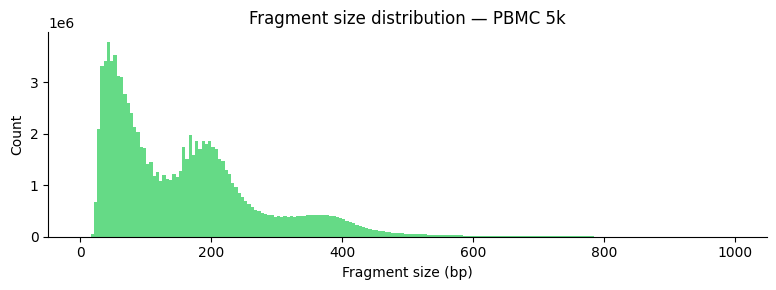

In [4]:
ga.pl.fragment_size_distribution(parquet_path, title="Fragment size distribution — PBMC 5k")

## 3. Quality metrics

In [5]:
GTF = "data/gencode.v44.primary_assembly.annotation.gtf.gz"

t0 = time.perf_counter()
metrics = ga.pp.compute_metrics(
    parquet_path,
    GTF,
    window_size=2000,
    smooth_window=11,
    min_unique_frags=500,
    exclude_chroms=["chrM", "M"],
    row_groups_per_batch=64,
)
print(f"Computed metrics for {len(metrics):,} barcodes in {time.perf_counter() - t0:.1f}s")
metrics_pd = metrics.to_pandas()


01:44:38 - gatac.pp.metrics - INFO - Loading TSS from data/gencode.v44.primary_assembly.annotation.gtf.gz


01:44:40 - gatac.pp.metrics - INFO - Loaded 219,362 unique TSSs


01:44:40 - gatac.pp.metrics - INFO - Computing metrics of pbmc_fragments.parquet (streaming mode, row_groups_per_batch=64)


01:44:44 - gatac.pp.metrics - INFO - Found 6,604 cells with >= 500 unique fragments


01:44:44 - gatac.pp.metrics - INFO - Processing 102 row groups in batches of 64...


01:44:47 - gatac.pp.metrics - INFO -   Processed row groups 102/102


01:44:47 - gatac.pp.metrics - INFO - Completed TSSe computation


Computed metrics for 6,604 barcodes in 10.1s


The equivalent cli command would be:
```bash
gatac metrics data/pbmc_fragments.parquet \
    -g data/gencode.v44.primary_assembly.annotation.gtf.gz
```
Saving metrics to `data/pbmc_fragments_metrics.csv` by default.

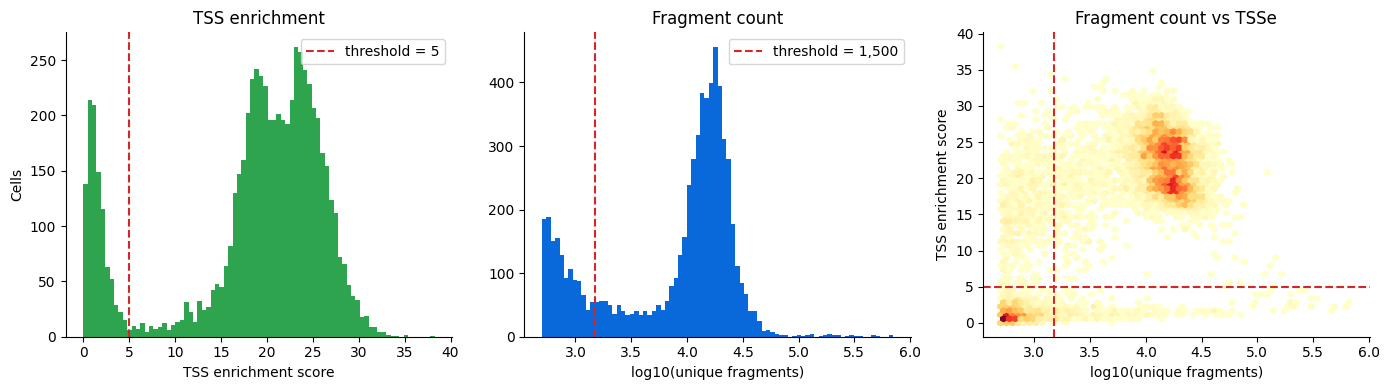

In [6]:
ga.pl.qc_metrics(metrics, tsse_threshold=5, n_unique_threshold=1500)

## 4. Filter QC & scan the tiles

We keep the fragment file with every barcode and filter out low-quality cells while binning the genome into 500 bp tiles, counting unique fragment insertions per cell with the SnapATAC2-compatible `"unique"` strategy.

The tile matrix is built in three steps, so that the number of tiles to keep can be chosen before any matrix is built. `scan_tiles` reads the fragments once and returns an AnnData **without a matrix**: the cells in `obs`, and in `var` every tile with its statistics over all cells — `n_cells` (cells with signal in the tile), `count` (sum of their counts) and `count_sq` (sum of the squares).

In [7]:
t0 = time.perf_counter()
tiles = ga.pp.scan_tiles(
    parquet_path,
    chrom_sizes="hg38",
    metrics=metrics,
    filter_query="(n_unique >= 1500) & (tsse_score >= 5)",
    tile_size=500,
    exclude_chroms=["chrM", "chrY"],
    count_strategy="unique",
)
print(f"Tiles scanned in {time.perf_counter() - t0:.1f}s")
print(tiles)
print("X:", tiles.X)
tiles.var.head()

01:44:58 - gatac.pp.tile_scan - INFO - Scanned pbmc_fragments.parquet: 5,001 cells


01:45:00 - gatac.pp.tile_scan - INFO - Scanned 1 files: 5,001 cells × 6,062,095 tiles (8.1s)


Tiles scanned in 11.6s
AnnData object with n_obs × n_vars = 5001 × 6062095
    obs: 'barcode', 'source_file', 'n_unique', 'tsse_score', 'duplicate_fraction', 'mito_fraction'
    var: 'chrom', 'start', 'end', 'n_cells', 'count', 'count_sq'
    uns: 'tile_stats', 'tile_scan'
X: None


,chrom,start,end,n_cells,count,count_sq
chr1:0-500,chr1,0,500,0,0,0
chr1:500-1000,chr1,500,1000,0,0,0
chr1:1000-1500,chr1,1000,1500,0,0,0
chr1:1500-2000,chr1,1500,2000,0,0,0
chr1:2000-2500,chr1,2000,2500,0,0,0


## 5. Choosing the number of tiles

Before selecting, the tiles' accessibility (`count`, the sum of their insertion counts over all cells) shows how many tiles carry signal. Ranked from the most accessible, it falls off steeply; the cumulative share of all insertions tells how much of the signal the top `N` tiles keep.

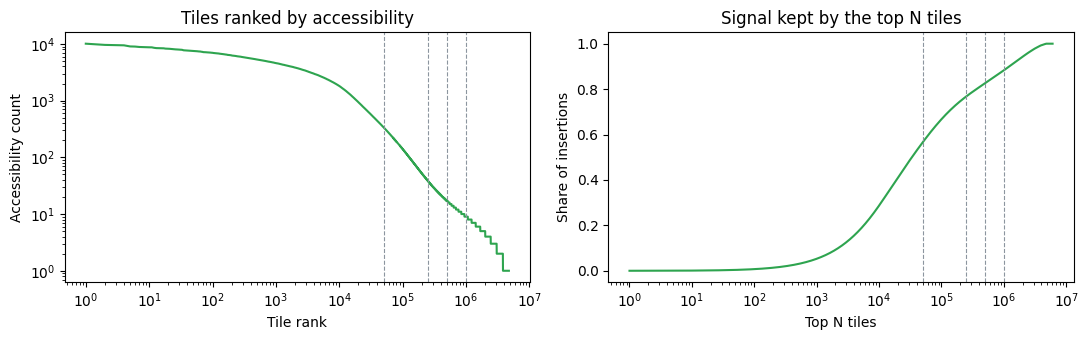

     top N  count at N  insertions kept
    50,000         338            56.5%
   250,000          38            76.8%
   500,000          17            82.6%
 1,000,000           9            88.2%
4,750,700 of 6,062,095 tiles have any signal


In [8]:
count = np.sort(tiles.var["count"].to_numpy())[::-1]
rank = np.arange(1, len(count) + 1)
covered = np.cumsum(count) / count.sum()
candidates = [50_000, 250_000, 500_000, 1_000_000]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].loglog(rank[count > 0], count[count > 0], color="#2ea44f")
axes[0].set_xlabel("Tile rank")
axes[0].set_ylabel("Accessibility count")
axes[0].set_title("Tiles ranked by accessibility")
axes[1].semilogx(rank, covered, color="#2ea44f")
axes[1].set_xlabel("Top N tiles")
axes[1].set_ylabel("Share of insertions")
axes[1].set_title("Signal kept by the top N tiles")
for ax in axes:
    for n in candidates:
        ax.axvline(n, color="#8c959f", lw=0.8, ls="--")
plt.tight_layout()
plt.show()

print(f"{'top N':>10}  {'count at N':>10}  {'insertions kept':>15}")
for n in candidates:
    print(f"{n:>10,}  {count[n - 1]:>10,}  {covered[n - 1]:>15.1%}")
print(f"{(count > 0).sum():,} of {len(count):,} tiles have any signal")

`select_features` keeps the top `n_features` most accessible tiles after removing empty tiles and the very rare (<0.5th percentile) and ubiquitously open (>99.5th percentile) ones, as SnapATAC2 does. On a `scan_tiles` result it reads only `var`, so it takes no time; any other criterion on the `var` statistics can set `tiles.var["selected"]` instead.

In [9]:
t0 = time.perf_counter()
ga.pp.select_features(tiles, n_features=500_000)
print(f"Feature selection in {time.perf_counter() - t0:.2f}s")

n_selected = tiles.var["selected"].sum()
print(f"Selected {n_selected:,} / {tiles.n_vars:,} tiles")

01:45:02 - gatac.pp.features - INFO - Selecting features from 6,062,095 total


01:45:02 - gatac.pp.features - INFO - Using the tile statistics of var


01:45:03 - gatac.pp.features - INFO - Detected count matrix - using quantile-filtered selection


01:45:03 - gatac.pp.features - INFO - Selected 500,000 features


Feature selection in 0.98s
Selected 500,000 / 6,062,095 tiles


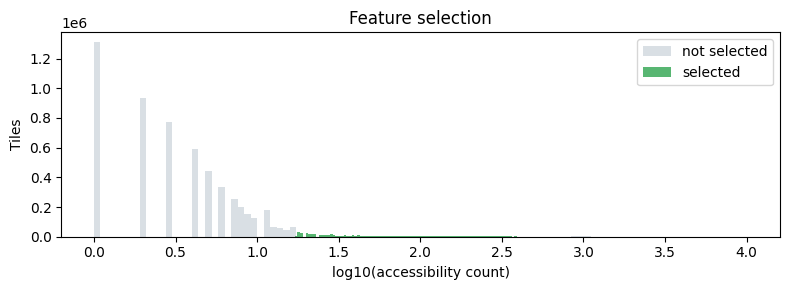

In [10]:
# Highlight selected tiles
fig, ax = plt.subplots(figsize=(8, 3))

is_selected = tiles.var["selected"].values
counts = tiles.var["count"].values

ax.hist(np.log10(counts[~is_selected] + 1), bins=100,
        color="#d0d7de", edgecolor="none", label="not selected", alpha=0.8)
ax.hist(np.log10(counts[is_selected] + 1), bins=100,
        color="#2ea44f", edgecolor="none", label="selected", alpha=0.8)
ax.set_xlabel("log10(accessibility count)")
ax.set_ylabel("Tiles")
ax.set_title("Feature selection")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Build the tile matrix of the selected tiles

`build_tile_matrix` reads the fragments again and builds the matrix of the selected tiles only; the matrix of every tile is never built. The statistics stay in `var`.

In [11]:
t0 = time.perf_counter()
adata = ga.pp.build_tile_matrix(tiles)
print(f"Tile matrix built in {time.perf_counter() - t0:.1f}s")
print(adata)

01:45:06 - gatac.pp.tile_scan - INFO - Built pbmc_fragments.parquet: 5,001 cells


01:45:07 - gatac.pp.tile_scan - INFO - Built 5,001 cells × 500,000 tiles (1.3s)


Tile matrix built in 3.1s
AnnData object with n_obs × n_vars = 5001 × 500000
    obs: 'barcode', 'source_file', 'n_unique', 'tsse_score', 'duplicate_fraction', 'mito_fraction'
    var: 'chrom', 'start', 'end', 'n_cells', 'count', 'count_sq', 'selected', 'accessibility_count'
    uns: 'tile_scan', 'tile_stats'


In [12]:
# Summary stats
print(f"Cells:    {adata.n_obs:,}")
print(f"Tiles:    {adata.n_vars:,}")
print(f"Density:  {adata.X.nnz / (adata.n_obs * adata.n_vars) * 100:.2f}%")

Cells:    5,001
Tiles:    500,000
Density:  1.50%


`make_tile_matrix` runs the three steps in one call when given `n_features`:

```python
adata = ga.pp.make_tile_matrix(
    parquet_path, chrom_sizes="hg38", metrics=metrics,
    filter_query="(n_unique >= 1500) & (tsse_score >= 5)",
    tile_size=500, exclude_chroms=["chrM", "chrY"], n_features=500_000,
)
```

and so does the CLI with `-n`:

```bash
gatac tile data/pbmc_fragments.parquet -g hg38 -t 500 -e chrM chrY -n 500000 \
    --metrics data/pbmc_fragments_metrics.csv \
    --filter "(n_unique >= 1500) & (tsse_score >= 5)"
```

By default, the tile matrix is saved to `data/pbmc_fragments_tile_matrix.h5ad`. Without `-n` (or `n_features`), every tile is kept.

If you prefer to filter the parquet file before tiling:

```bash
gatac filter data/pbmc_fragments.parquet \
    --metrics data/pbmc_fragments_metrics.csv \
    --filter "(n_unique >= 1500) & (tsse_score >= 5)"
gatac tile data/pbmc_fragments_filtered.parquet -g hg38 -t 500 -n 500000
```

For several samples, `gatac tile` takes all their fragment files and builds one matrix, selecting the tiles on all cells together, without per-sample matrices:

```bash
gatac tile sample*_filtered.parquet -g hg38 -n 500000 -o combined.h5ad
```

or in Python, `ga.pp.make_tile_matrix([...], chrom_sizes="hg38", n_features=500_000, output_path="combined.h5ad")`. The samples must not share cell names: give each its own barcode prefix, when converting or afterwards with `gatac rename`, which rewrites the file footer only.

## 7. Save

In [13]:
adata.write_h5ad("data/pbmc_tile.h5ad")
print("Saved → data/pbmc_tile.h5ad")

Saved → data/pbmc_tile.h5ad


## Next steps

- [02 – Spectral embedding](02_embedding_peak_calling.ipynb): dimensionality reduction and clustering